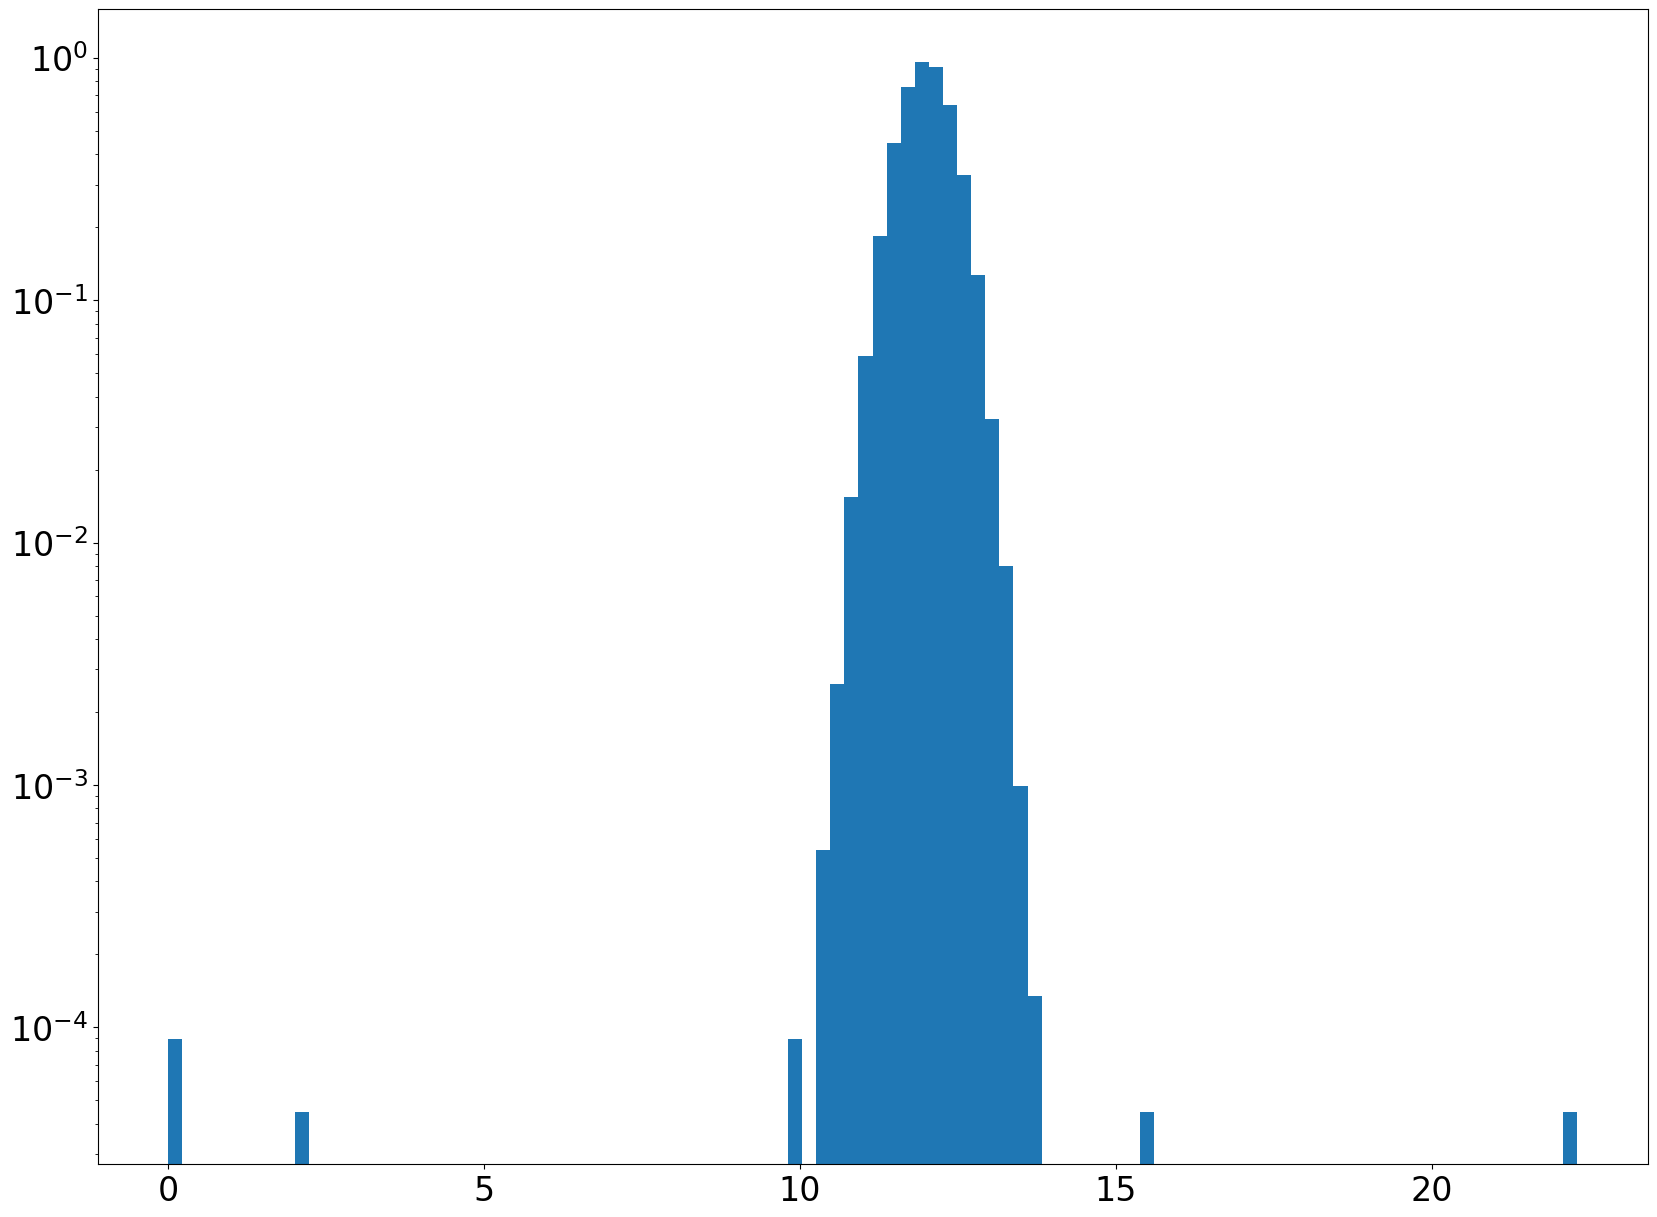

In [1]:
%matplotlib inline
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import scipy
from scipy import stats

#this sets the size of the plot to something useful
plt.rcParams["figure.figsize"] = (20,15)

d = np.append(stats.norm.rvs(loc = 12., scale = 0.4, size = 100000), [10., 10.3, 2.1, 0., 0., 15.6, 22.3, 12.7])
fig, ax = plt.subplots(1, 1)
ax.hist(d,100, density=True)
plt.tick_params(labelsize = 24)
plt.yscale('log')
#x = np.linspace(4.95,5.05,1000)
#ax.plot(x,stats.norm.pdf(x,loc = 5., scale = 0.01),linewidth = 8,alpha = 0.7)
plt.show()

In [3]:
#Problem 1

#(a)
print("Problem 1 (a)")
# If our experiment is supposed to operate at 12K with a standard deviation
# of 0.4K, how likely is a temperature measurement to be this far from 12K
# if the experiment is working properly?
# A 3 sigma threshold was chosen to identify measurements that are
# unusually far from the expected temperature.
good_data = np.abs(d - 12) <= 1.2
correctly_kept = np.sum(good_data[:100000])
incorrectly_rejected = 100000 - correctly_kept
incorrectly_accepted = np.sum(good_data[100000:])
correctly_rejected = 8 - incorrectly_accepted
print("Correctly kept:", correctly_kept)
print("Incorrectly rejected:", incorrectly_rejected)
print("Incorrectly accepted:", incorrectly_accepted)
print("Correctly rejected:", correctly_rejected)

Correctly kept: 99711
Incorrectly rejected: 289
Incorrectly accepted: 1
Correctly rejected: 7


In [7]:
print("(b)")

n = 3
N = 100000

prob_omission = 2 * stats.norm.sf(n)
expected_omissions = N * prob_omission

n = 4

expected = 100000 * 2 * stats.norm.sf(n)


print("Number of Omissions for 3 sigma", expected_omissions)
print("Number of Omissions for 4 sigma", expected)
print("It's predictable because it follows a Gaussian distribution, so just do a survival function of the number of sigma multiplied by the total count of measurements.")

(b)
Number of Omissions for 3 sigma 269.97960632601865
Number of Omissions for 3 sigma 6.334248366623973


In [9]:
print("(c)")
print("There was one bad measuremt (12.7 K), which was within our 3 sigma range, that was kept as a measurement.")
print("This could simply be prevented by reducing the range of the measurements being kept (from 3 sigma --> 1.5 sigma), therefore the new range is")
print("11.4 < T < 12.6")
print("However, this would also mean that a lot of GOOD measurements would no longer be kept in our dataset.")

(c)
There was one bad measuremt (12.7 K), which was within our 3 sigma range, that was kept as a measurement.
This could simply be prevented by reducing the range of the measurements being kept (from 3 sigma --> 1.5 sigma), therefore the new range is
11.4 < T < 12.6
However, this would also mean that a lot of GOOD measurements would no longer be kept in our dataset.


Problem 2 (a)


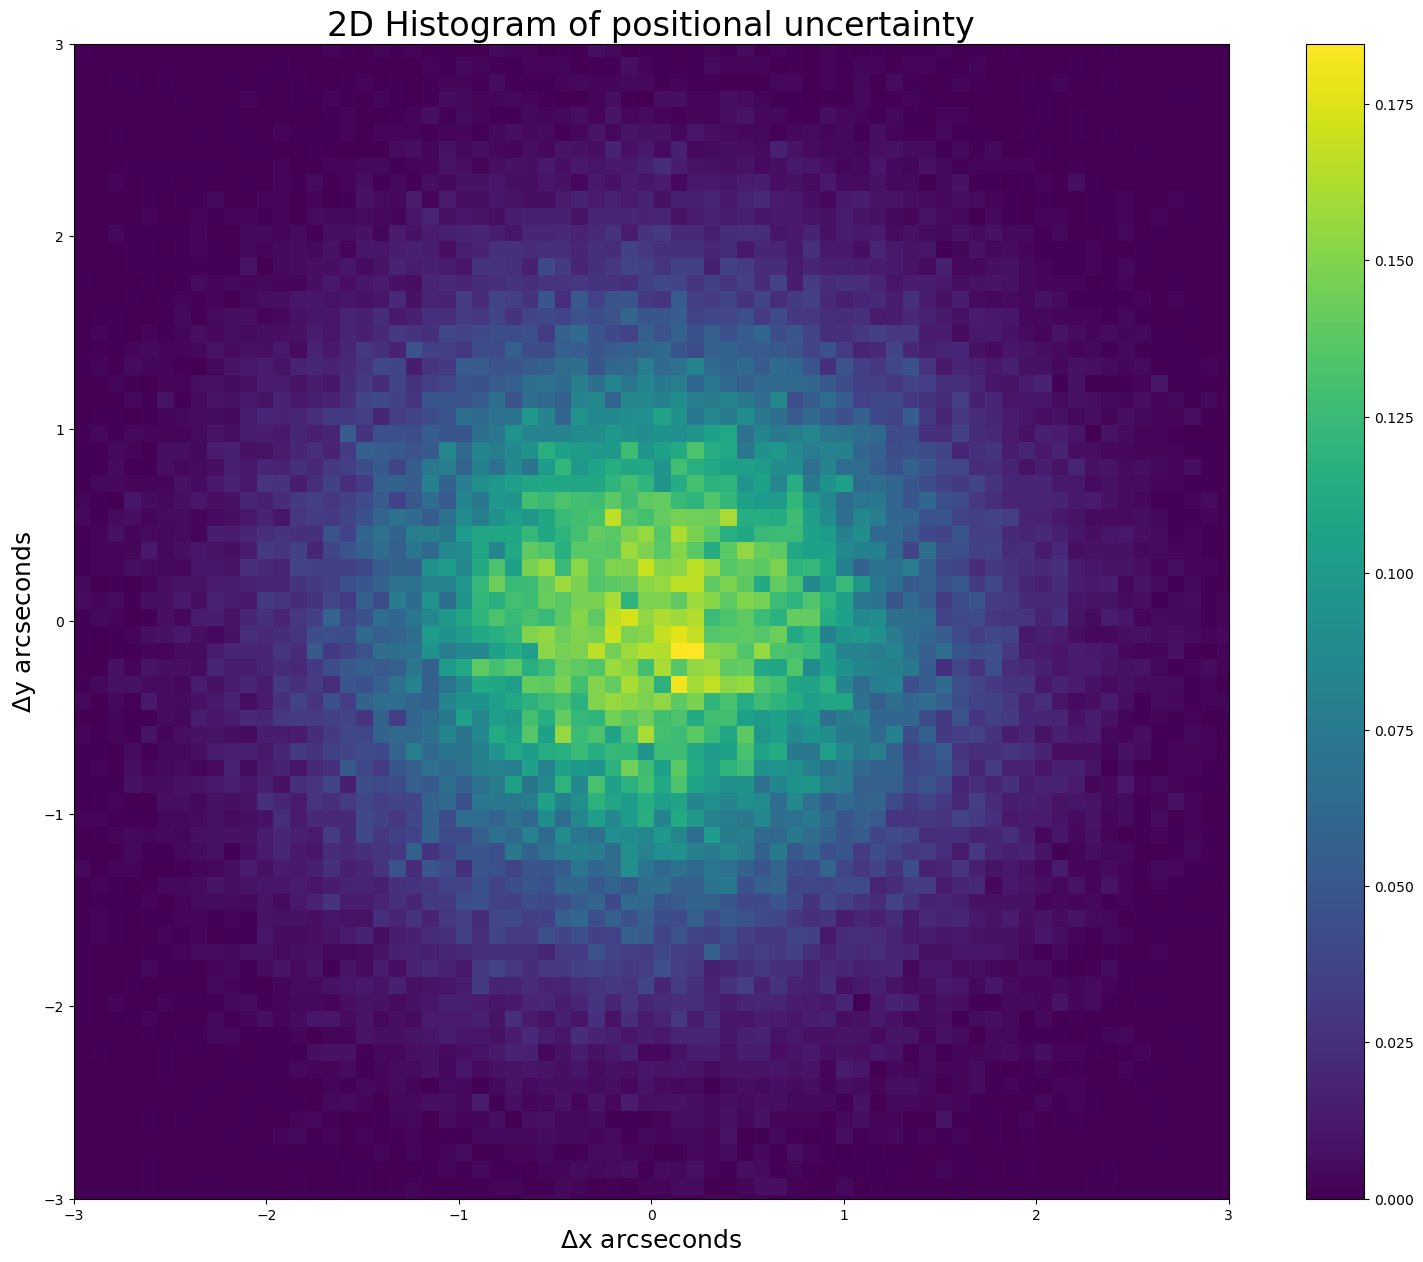

In [11]:
print("Problem 2")
a = np.vstack((stats.norm.rvs( scale = 1, size = 100000), stats.norm.rvs( scale = 1, size = 100000)))
a.shape
fig, ax = plt.subplots(1, 1)
h = ax.hist2d(a[0,:],a[1,:],bins=100, density=True);
ax.set_aspect('equal', 'box')
plt.xlim([-3 , 3])
plt.ylim([-3 , 3])
plt.title("2D Histogram of positional uncertainty", fontsize = 24)
plt.ylabel(r"$\Delta$y arcseconds", fontsize = 18)
plt.xlabel(r"$\Delta$x arcseconds", fontsize = 18)
plt.colorbar(h[3], ax=ax)

In [13]:
print("(a)")

print("If an object is actually stationary, what is the probability that random measurement errors would make it appear to move by at least a certain distance?")

print("(b)")

print("The survival function of the Rayleigh Distribution or PDF, from (insert movement parameter (ie. 2 arcseconds)) to infinity.")

print("(c)")

p_5sigma = stats.norm.sf(5)

distance = stats.rayleigh.isf(p_5sigma, scale=1)

print("5 sigma distance:", distance, "arcseconds")


(a)
If an object is actually stationary, what is the probability that random measurement errors would make it appear to move by at least a certain distance?
(b)
The survival function of the Rayleigh Distribution or PDF, from (insert movement parameter (ie. 2 arcseconds)) to infinity.
(c)
5 sigma distance: 5.489079776062419 arcseconds


In [19]:
print("Problem 3")
print("(a)")
print("If the Moon were not blocking any cosmic rays, what is the probability that random fluctuations in the arrival of cosmic rays would cause us to observe 6,800 or fewer cosmic rays, when we expect 7,200?")
print("(b)")
print("Since you're using the Poisson distribution, it's technically not an integral but a sum, because Poission distributions deal with discrete values. \nHence, assuming that the mean is 7200, find the probability that you find less than 6800 cosmic events on a poisson distribution.")
expected = 7200
observed = 6800

probability = stats.poisson.cdf(observed, mu=expected)

print(probability)
print("(c)")
print(f"{stats.norm.isf(probability)} sigma")

Problem 3
(a)
If the Moon were not blocking any cosmic rays, what is the probability that random fluctuations in the arrival of cosmic rays would cause us to observe 6,800 or fewer cosmic rays, when we expect 7,200?
(b)
Since you're using the Poisson distribution, it's technically not an integral but a sum, because Poission distributions deal with discrete values. 
Hence, assuming that the mean is 7200, find the probability that you find less than 6800 cosmic events on a poisson distribution.
1.0133280183917768e-06
(c)
4.750747965777188
